# Spiking Transformer (A²OS²A) with Quantized, Learnable-Step K — FAST version

**Base paper:** *Spiking Transformer: Introducing Accurate Addition-Only Spiking Self-Attention for Transformer* (A²OS²A, CVPR 2025).
**Our contribution:** replace the paper's full-precision ReLU **K** with a **b-bit spiking neuron with a learnable per-channel step size**. Q stays binary, V stays ternary, no softmax, no scaling. This notebook runs **b = 1 and b = 3** against the paper's full-precision K on CIFAR-10 / CIFAR-100.

**What was changed to make it much faster (the algorithm itself is unchanged):**

| Change | Why it is faster |
|---|---|
| Encoder depth 4 → 2, time steps T 4 → 2 (default `fast` preset) | ~4x fewer layer evaluations in the Python time-step loops |
| Patch-splitting module pools earlier (32→16→8 instead of 32→32→16→8) | The expensive convolutions now run at 16×16 / 8×8 instead of 32×32 / 16×16 |
| Batch size 128 → 256, 30 → 20 epochs | Fewer, better-utilised GPU steps |
| Single GPU (no `DataParallel`) | DataParallel copies a small model every step and is often *slower* here |
| No `.item()` GPU sync inside the training loop; test accuracy every 2 epochs | Removes pipeline stalls |
| Only b = 1, 3 (plus the paper's FP-K baseline for comparison) | 3 runs per dataset instead of 5 |

**Kaggle:** attach the *CIFAR-10* and *cifar-100-image-dataset-original* datasets, pick a **GPU (T4 / P100)**, then *Run All*.

## 0. GPU check

In [9]:
import subprocess
try: print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout or "no GPU found")
except Exception: print("nvidia-smi not available")

GPU 0: Tesla T4 (UUID: GPU-dfdf8bd4-86e6-03e8-048b-1f714f51d884)
GPU 1: Tesla T4 (UUID: GPU-8a1a5ce3-fc5b-48d5-99de-754c8df602db)



## 1. Settings
Everything you may want to change is in this one cell.

In [10]:
import os, sys, math, time, json, random, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
warnings.filterwarnings("ignore")

# ======================================================================
#                         USER SETTINGS  (edit here)
# ======================================================================
INPUT_ROOT    = "/kaggle/input"
WORK_DIR      = "/kaggle/working"
CIFAR10_ROOT  = None      # None = auto-detect; else the folder that CONTAINS 'train' and 'test'
CIFAR100_ROOT = None

PRESET      = "fast"                 # 'smoke' (1-min test) | 'fast' (default) | 'balanced' (a bit slower, a bit more accurate)
DATASETS    = ["cifar10", "cifar100"]
BITS_SWEEP  = [1, 3]                 # only b = 1 and b = 3
RUN_PAPER_BASELINE = True            # paper's full-precision ReLU K (needed for the comparison; set False to save ~1/3 of the time)
EPOCHS_OVERRIDE    = None            # e.g. 10 to shorten every run
SEED        = 42
USE_MULTI_GPU = False                # DataParallel is usually slower for this small model
ATTN_VTH    = 0.5                    # firing threshold after Q.K^T.V (replaces 1/sqrt(d) scaling and softmax)
ACC_TOLERANCE_PP = 0.5               # "nearly matches full-precision K" = within this many points
EVAL_EVERY  = 2                      # test accuracy every N epochs (always on the last epoch)
# ======================================================================

COMMON = dict(mlp_ratio=4, tau=2.0, label_smoothing=0.1, clip=1.0)
PRESETS = {
    "smoke":    dict(embed=64,  depth=1, heads=4, T=2, epochs=1,  bs=64,  lr=1e-3,   wd=0.05, warmup=0, train_subset=512, test_subset=256),
    "fast":     dict(embed=256, depth=2, heads=8, T=2, epochs=20, bs=256, lr=1.5e-3, wd=0.05, warmup=1, train_subset=None, test_subset=None),
    "balanced": dict(embed=256, depth=2, heads=8, T=4, epochs=25, bs=256, lr=1.5e-3, wd=0.05, warmup=1, train_subset=None, test_subset=None),
}
CFG = {**COMMON, **PRESETS[PRESET]}
if EPOCHS_OVERRIDE is not None: CFG["epochs"] = int(EPOCHS_OVERRIDE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU  = torch.cuda.device_count()
AMP    = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
os.makedirs(WORK_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

print("torch", torch.__version__, "| device:", DEVICE, "| GPUs:", N_GPU)
print("PRESET =", PRESET, "->", {k: CFG[k] for k in ["embed","depth","heads","T","epochs","bs","lr"]})

torch 2.11.0+cu130 | device: cuda | GPUs: 2
PRESET = fast -> {'embed': 256, 'depth': 2, 'heads': 8, 'T': 2, 'epochs': 20, 'bs': 256, 'lr': 0.0015}


## 2. Data
Images are decoded once, cached in `WORK_DIR`, kept on the GPU as uint8, and augmented on the GPU (random crop with 4-px padding + horizontal flip). Class = parent folder name.

In [11]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
MEAN_STD = {
    "cifar10":  ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
    "cifar100": ((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)),
}
EXPECTED = {"cifar10": (10, 50000, 10000), "cifar100": (100, 50000, 10000)}

def _find_split_pairs(root, max_depth=6):
    pairs, root = [], os.path.abspath(root)
    base = root.count(os.sep)
    for dp, dns, _ in os.walk(root):
        if dp.count(os.sep) - base >= max_depth:
            dns[:] = []; continue
        low = {d.lower(): d for d in dns}
        if "train" in low and "test" in low:
            pairs.append((os.path.join(dp, low["train"]), os.path.join(dp, low["test"])))
            dns[:] = []
    return pairs

def locate_dataset(name):
    override = CIFAR10_ROOT if name == "cifar10" else CIFAR100_ROOT
    pairs = _find_split_pairs(override or INPUT_ROOT)
    if override is None:
        want100 = (name == "cifar100")
        pairs = [p for p in pairs if ("100" in p[0].lower()) == want100]
    if not pairs:
        raise FileNotFoundError(f"Could not find train/test folders for {name}. Set CIFAR10_ROOT / CIFAR100_ROOT in the settings cell.")
    if len(pairs) > 1: print(f"[{name}] several candidates, using the first: {pairs}")
    return pairs[0]

def _scan(split_dir):
    files = []
    for dp, _, fns in os.walk(split_dir):
        for fn in fns:
            if os.path.splitext(fn)[1].lower() in IMG_EXT: files.append(os.path.join(dp, fn))
    files.sort()
    return files, [os.path.basename(os.path.dirname(f)) for f in files]

def _decode(path):
    with Image.open(path) as im:
        im = im.convert("RGB")
        if im.size != (32, 32): im = im.resize((32, 32), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

def load_dataset(name):
    cache = os.path.join(WORK_DIR, f"cache_{name}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return dict(xtr=z["xtr"], ytr=z["ytr"], xte=z["xte"], yte=z["yte"], classes=list(z["classes"]))
    tr_dir, te_dir = locate_dataset(name)
    print(f"[{name}] train dir: {tr_dir}\n[{name}] test  dir: {te_dir}")
    ftr, ntr = _scan(tr_dir); fte, nte = _scan(te_dir)
    if not ftr or not fte: raise RuntimeError(f"No images found under {tr_dir} / {te_dir} (expected train/<class>/*.png).")
    classes = sorted(set(ntr))
    if len(classes) < 2: raise RuntimeError(f"Found only {len(classes)} class folder(s) in {tr_dir}; expected train/<class_name>/*.png.")
    c2i = {c: i for i, c in enumerate(classes)}
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=16) as ex:
        xtr = np.stack(list(ex.map(_decode, ftr))); xte = np.stack(list(ex.map(_decode, fte)))
    ytr = np.array([c2i[n] for n in ntr], dtype=np.int64); yte = np.array([c2i[n] for n in nte], dtype=np.int64)
    ec, etr, ete = EXPECTED[name]
    print(f"[{name}] decoded {len(xtr)} train / {len(xte)} test, {len(classes)} classes in {time.time()-t0:.0f}s")
    if len(classes) != ec or len(xtr) != etr or len(xte) != ete:
        print(f"  WARNING: expected {ec} classes / {etr} train / {ete} test")
    np.savez(cache, xtr=xtr, ytr=ytr, xte=xte, yte=yte, classes=np.array(classes))
    return dict(xtr=xtr, ytr=ytr, xte=xte, yte=yte, classes=classes)

class GPUData:
    def __init__(self, name, cfg):
        d = load_dataset(name)
        self.name, self.classes = name, d["classes"]; self.num_classes = len(self.classes)
        xtr, ytr, xte, yte = d["xtr"], d["ytr"], d["xte"], d["yte"]
        if cfg.get("train_subset"):
            i = np.random.RandomState(0).permutation(len(xtr))[:cfg["train_subset"]]; xtr, ytr = xtr[i], ytr[i]
        if cfg.get("test_subset"):
            i = np.random.RandomState(1).permutation(len(xte))[:cfg["test_subset"]]; xte, yte = xte[i], yte[i]
        to = lambda a: torch.from_numpy(a).to(DEVICE)
        self.xtr, self.ytr = to(xtr).permute(0, 3, 1, 2).contiguous(), to(ytr)
        self.xte, self.yte = to(xte).permute(0, 3, 1, 2).contiguous(), to(yte)
        m, s = MEAN_STD[name]
        self.mean = torch.tensor(m, device=DEVICE).view(1, 3, 1, 1); self.std = torch.tensor(s, device=DEVICE).view(1, 3, 1, 1)

    def _norm(self, x): return (x.float().div_(255.0) - self.mean) / self.std

    @staticmethod
    def _augment(x, pad=4):
        B, C, H, W = x.shape
        xp = F.pad(x, (pad, pad, pad, pad))
        i = torch.randint(0, 2 * pad + 1, (B,), device=x.device); j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
        rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
        cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
        out = xp[torch.arange(B, device=x.device)[:, None, None, None], torch.arange(C, device=x.device)[None, :, None, None], rows, cols]
        flip = torch.rand(B, device=x.device) < 0.5
        return torch.where(flip[:, None, None, None], out.flip(3), out)

    def train_batches(self, bs):
        idx = torch.randperm(len(self.xtr), device=DEVICE)
        for k in range(0, len(idx) - bs + 1, bs):
            b = idx[k:k + bs]
            yield self._augment(self._norm(self.xtr[b])), self.ytr[b]

    def test_batches(self, bs=512):
        for k in range(0, len(self.xte), bs):
            yield self._norm(self.xte[k:k + bs]), self.yte[k:k + bs]

_DATA_CACHE = {}
def get_data(name):
    if name not in _DATA_CACHE: _DATA_CACHE[name] = GPUData(name, CFG)
    return _DATA_CACHE[name]

## 3. Model
Same neurons and attention as before: binary Q, **K = ReLU (paper) or b-bit learnable-step spiking neuron (ours)**, ternary V, output = neuron(Q·Kᵀ·V) with no softmax and no scaling. The only structural change is a lighter patch-splitting module (earlier pooling) and a shallower encoder.

In [12]:
class _SpikeFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.save_for_backward(x); ctx.alpha = alpha
        return (x >= 0).to(x.dtype)
    @staticmethod
    def backward(ctx, g):
        (x,) = ctx.saved_tensors; a = ctx.alpha
        return g * (a / 2) / (1 + (math.pi / 2 * a * x) ** 2), None

def spike_fn(x, alpha=2.0): return _SpikeFn.apply(x, alpha)
def grad_scale(x, s): return (x - x * s).detach() + x * s
def round_ste(x): return (torch.round(x) - x).detach() + x


class SpikingNeuron(nn.Module):
    """Multi-step LIF (tau=2, hard reset). binary -> {0,1}; ternary -> {-1,0,+1} (used for V)."""
    def __init__(self, mode="binary", tau=2.0, vth=1.0, alpha=2.0):
        super().__init__(); self.mode, self.tau, self.vth, self.alpha = mode, tau, vth, alpha
    def forward(self, x):
        dt = x.dtype; x = x.float()
        v = torch.zeros_like(x[0]); outs = []
        for t in range(x.shape[0]):
            v = v + (x[t] - v) / self.tau
            if self.mode == "binary":
                s = spike_fn(v - self.vth, self.alpha); v = v * (1.0 - s.detach())
            else:
                s = spike_fn(v - self.vth, self.alpha) - spike_fn(-v - self.vth, self.alpha); v = v * (1.0 - s.detach().abs())
            outs.append(s)
        return torch.stack(outs, 0).to(dt)


class MultiBitSpikingNeuron(nn.Module):
    """OUR CONTRIBUTION: b-bit spiking neuron for K with a LEARNABLE PER-CHANNEL STEP SIZE.
       n_t = clip(round(v_t / theta_c), 0, 2^b - 1),  soft reset v_t <- v_t - n_t*theta_c,  K_t = n_t*theta_c.
       -> bounded, 2^b levels per channel. Q is binary, so Q.K^T is still pure accumulation (no multiplications)."""
    def __init__(self, channels, bits, tau=2.0):
        super().__init__()
        self.C, self.bits, self.tau = channels, bits, tau
        self.L = 2 ** bits - 1
        self.theta = nn.Parameter(torch.full((channels,), 1.6 / math.sqrt(self.L)))
    def step_size(self): return self.theta.abs() + 1e-4
    def forward(self, x):
        x = x.float(); th = self.step_size()
        n_per_ch = x[0].numel() // self.C
        th = grad_scale(th, 1.0 / math.sqrt(n_per_ch * self.L))
        v = torch.zeros_like(x[0]); outs = []
        for t in range(x.shape[0]):
            v = v + (x[t] - v) / self.tau
            n = torch.clamp(round_ste(v / th), 0, self.L)
            k = n * th
            v = v - k.detach()
            outs.append(k)
        return torch.stack(outs, 0)


class BNLast(nn.Module):
    def __init__(self, c): super().__init__(); self.bn = nn.BatchNorm1d(c)
    def forward(self, x):
        s = x.shape; return self.bn(x.reshape(-1, s[-1])).reshape(s)


class SpikingSelfAttention(nn.Module):
    """k_mode='relu' -> paper's full-precision K (BASELINE);  k_mode='quant' -> our b-bit learnable-step K."""
    def __init__(self, dim, heads, cfg, tau=2.0):
        super().__init__()
        self.dim, self.heads, self.cfg = dim, heads, cfg
        self.q_lin, self.q_bn = nn.Linear(dim, dim, bias=False), BNLast(dim)
        self.k_lin, self.k_bn = nn.Linear(dim, dim, bias=False), BNLast(dim)
        self.v_lin, self.v_bn = nn.Linear(dim, dim, bias=False), BNLast(dim)
        self.q_neuron = SpikingNeuron("binary", tau)
        self.k_act = nn.ReLU() if cfg["k_mode"] == "relu" else MultiBitSpikingNeuron(dim, cfg["k_bits"], tau)
        self.v_neuron = SpikingNeuron("ternary", tau)
        self.attn_neuron = SpikingNeuron("binary", tau, vth=cfg["attn_vth"])
        self.proj_lin, self.proj_bn = nn.Linear(dim, dim, bias=False), BNLast(dim)
        self.collect, self.stat, self.last = False, {}, {}

    def forward(self, x):                                   # x: [T, B, N, C]
        T, B, N, C = x.shape; H, d = self.heads, C // self.heads
        q = self.q_neuron(self.q_bn(self.q_lin(x)))
        k = self.k_act(self.k_bn(self.k_lin(x)))
        v = self.v_neuron(self.v_bn(self.v_lin(x)))
        split = lambda z: z.float().reshape(T, B, N, H, d).permute(0, 1, 3, 2, 4)
        with torch.autocast("cuda", enabled=False):
            q, k, v = split(q), split(k), split(v)
            out = (q @ k.transpose(-2, -1)) @ v             # no softmax, no scaling; binary Q / ternary V -> additions only
        if self.collect:
            with torch.no_grad():
                nq, nv = (q != 0).float().sum().item(), (v != 0).float().sum().item()
                self.stat = dict(q_rate=(q != 0).float().mean().item(), k_rate=(k != 0).float().mean().item(),
                                 v_rate=(v != 0).float().mean().item(), acs_per_sample=(nq + nv) * N / B)
                self.last = dict(q=q[:, :1].cpu(), k=k[:, :1].cpu(), v=v[:, :1].cpu())
        out = out.permute(0, 1, 3, 2, 4).reshape(T, B, N, C)
        return self.proj_bn(self.proj_lin(self.attn_neuron(out)))


class MLP(nn.Module):
    def __init__(self, dim, ratio, tau):
        super().__init__(); hid = dim * ratio
        self.fc1, self.bn1, self.lif1 = nn.Linear(dim, hid, bias=False), BNLast(hid), SpikingNeuron("binary", tau)
        self.fc2, self.bn2 = nn.Linear(hid, dim, bias=False), BNLast(dim)
    def forward(self, x): return self.bn2(self.fc2(self.lif1(self.bn1(self.fc1(x)))))


class EncoderBlock(nn.Module):
    def __init__(self, dim, heads, ratio, attn_cfg, tau):
        super().__init__()
        self.lif_a = SpikingNeuron("binary", tau); self.attn = SpikingSelfAttention(dim, heads, attn_cfg, tau)
        self.lif_m = SpikingNeuron("binary", tau); self.mlp = MLP(dim, ratio, tau)
    def forward(self, u):
        u = u + self.attn(self.lif_a(u)).float()
        return u + self.mlp(self.lif_m(u)).float()


class SpikingPatchSplitting(nn.Module):
    """LIGHTER PSM + RPE: conv-BN, then 3 x [spike-conv-BN], max-pool after conv1 and conv2  (32 -> 16 -> 8 = 64 tokens).
       Pooling earlier means conv2/conv3 run at 16x16 / 8x8 instead of 32x32 / 16x16."""
    def __init__(self, dim, tau, in_ch=3):
        super().__init__()
        c = [dim // 8, dim // 4, dim // 2, dim]
        self.conv0, self.bn0 = nn.Conv2d(in_ch, c[0], 3, 1, 1, bias=False), nn.BatchNorm2d(c[0])
        self.lif1, self.conv1, self.bn1 = SpikingNeuron("binary", tau), nn.Conv2d(c[0], c[1], 3, 1, 1, bias=False), nn.BatchNorm2d(c[1])
        self.lif2, self.conv2, self.bn2 = SpikingNeuron("binary", tau), nn.Conv2d(c[1], c[2], 3, 1, 1, bias=False), nn.BatchNorm2d(c[2])
        self.lif3, self.conv3, self.bn3 = SpikingNeuron("binary", tau), nn.Conv2d(c[2], c[3], 3, 1, 1, bias=False), nn.BatchNorm2d(c[3])
        self.pool = nn.MaxPool2d(3, 2, 1)
        self.rpe_lif, self.rpe_conv, self.rpe_bn = SpikingNeuron("binary", tau), nn.Conv2d(dim, dim, 3, 1, 1, bias=False), nn.BatchNorm2d(dim)

    @staticmethod
    def _cb(lif, conv, bn, x, pool=None):
        x = lif(x); T, B = x.shape[:2]
        y = bn(conv(x.flatten(0, 1)))
        if pool is not None: y = pool(y)
        return y.reshape(T, B, *y.shape[1:])

    def forward(self, img, T):
        x = self.bn0(self.conv0(img))                       # analog (direct) encoding, computed once, repeated over T
        x = x.unsqueeze(0).expand(T, *x.shape).contiguous()
        x = self._cb(self.lif1, self.conv1, self.bn1, x, self.pool)     # 32 -> 16
        x = self._cb(self.lif2, self.conv2, self.bn2, x, self.pool)     # 16 -> 8
        x = self._cb(self.lif3, self.conv3, self.bn3, x)                # 8
        r = self._cb(self.rpe_lif, self.rpe_conv, self.rpe_bn, x)
        return (x + r).float().flatten(3).permute(0, 1, 3, 2)           # [T,B,N,C]


class SpikingTransformer(nn.Module):
    def __init__(self, num_classes, dim, depth, heads, T, mlp_ratio, attn_cfg, tau=2.0, amp=True):
        super().__init__()
        self.T, self.amp = T, amp
        self.sps = SpikingPatchSplitting(dim, tau)
        self.blocks = nn.ModuleList([EncoderBlock(dim, heads, mlp_ratio, attn_cfg, tau) for _ in range(depth)])
        self.out_lif = SpikingNeuron("binary", tau)
        self.head = nn.Linear(dim, num_classes)
    def forward(self, img):
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.amp):
            u = self.sps(img, self.T)
            for blk in self.blocks: u = blk(u)
            s = self.out_lif(u)
            return self.head(s.mean(2)).float().mean(0)

def count_params_m(model): return sum(p.numel() for p in model.parameters()) / 1e6
def unwrap(model): return model.module if isinstance(model, nn.DataParallel) else model

## 4. Sanity checks (should print `OK`)
Q ∈ {0,1}, V ∈ {−1,0,+1}, K uses at most 2^b levels, and (Q·Kᵀ)·V recomputed with **only additions/subtractions** equals the matrix product.

In [13]:
def make_attn_cfg(variant):
    return dict(k_mode=variant.get("k_mode", "relu"), k_bits=variant.get("k_bits", 0), attn_vth=ATTN_VTH)

def build_model(variant, num_classes, cfg):
    return SpikingTransformer(num_classes, cfg["embed"], cfg["depth"], cfg["heads"], cfg["T"],
                              cfg["mlp_ratio"], make_attn_cfg(variant), cfg["tau"], amp=AMP).to(DEVICE)

def addition_only_check(q, k, v):
    N, d = q.shape
    attn = torch.zeros(N, N)
    for i in range(N):
        cols = q[i] == 1
        for j in range(N): attn[i, j] = k[j, cols].sum()
    out = torch.zeros(N, v.shape[1])
    for c in range(v.shape[1]):
        pos, neg = v[:, c] == 1, v[:, c] == -1
        out[:, c] = attn[:, pos].sum(1) - attn[:, neg].sum(1)
    return out

def sanity_check(variant):
    cfg = {**CFG, "embed": 64, "depth": 1, "heads": 4, "T": 2}
    model = build_model(variant, 10, cfg).train()
    att = model.blocks[0].attn; att.collect = True
    with torch.no_grad(): y = model(torch.randn(16, 3, 32, 32, device=DEVICE))
    assert y.shape == (16, 10) and torch.isfinite(y).all()
    Q, K, V = att.last["q"], att.last["k"], att.last["v"]
    assert set(Q.unique().tolist()) <= {0.0, 1.0}, "Q must be binary"
    assert set(V.unique().tolist()) <= {-1.0, 0.0, 1.0}, "V must be ternary"
    msg = f"{variant['name']:<10} Q in {sorted(set(Q.unique().tolist()))}, V in {sorted(set(V.unique().tolist()))}"
    if variant["k_mode"] == "quant":
        th = att.k_act.step_size().detach().cpu().reshape(1, 1, att.heads, 1, -1)
        levels = torch.round(K / th).unique()
        assert levels.min() >= 0 and levels.max() <= 2 ** variant["k_bits"] - 1
        msg += f", K levels used (of {2**variant['k_bits']}): {levels.int().tolist()}"
    else:
        msg += f", K range = [{K.min().item():.2f}, {K.max().item():.2f}]"
    t = Q.shape[0] - 1
    ao = addition_only_check(Q[t, 0, 0][:16], K[t, 0, 0][:16], V[t, 0, 0][:16])
    assert torch.allclose(ao, (Q[t, 0, 0][:16] @ K[t, 0, 0][:16].T) @ V[t, 0, 0][:16], atol=1e-3)
    print(msg, "| addition-only == matmul: OK")

def make_variants():
    vs = []
    if RUN_PAPER_BASELINE: vs.append(dict(name="paper_fpK", label="Paper: full-precision ReLU K", k_mode="relu", k_bits=32))
    for b in BITS_SWEEP: vs.append(dict(name=f"ours_b{b}", label=f"Ours: {b}-bit learnable-step K", k_mode="quant", k_bits=b))
    return vs
VARIANTS = make_variants()

for v in VARIANTS: sanity_check(v)
m = build_model(VARIANTS[0], 100, CFG)
print(f"\nModel for preset '{PRESET}': {count_params_m(m):.2f} M parameters"); del m

paper_fpK  Q in [0.0, 1.0], V in [-1.0, 0.0, 1.0], K range = [0.00, 5.87] | addition-only == matmul: OK
ours_b1    Q in [0.0, 1.0], V in [-1.0, 0.0, 1.0], K levels used (of 2): [0, 1] | addition-only == matmul: OK
ours_b3    Q in [0.0, 1.0], V in [-1.0, 0.0, 1.0], K levels used (of 8): [0, 1, 2, 3, 5] | addition-only == matmul: OK

Model for preset 'fast': 2.59 M parameters


## 5. Training code
AdamW + cosine schedule with warm-up, label smoothing 0.1, fp16 autocast, gradient clipping. Checkpoints are written every epoch (interrupted sessions resume); finished runs are stored in `results.json` and skipped on re-run. The headline number is the **final-epoch** test accuracy.

In [14]:
RESULTS_PATH = os.path.join(WORK_DIR, "results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
def save_results():
    tmp = RESULTS_PATH + ".tmp"; json.dump(RESULTS, open(tmp, "w")); os.replace(tmp, RESULTS_PATH)

def run_id(ds, variant, cfg):
    return f"{ds}|{variant['name']}|d{cfg['embed']}-L{cfg['depth']}-T{cfg['T']}-ep{cfg['epochs']}"

@torch.no_grad()
def evaluate(model, data):
    model.eval(); correct = torch.zeros((), device=DEVICE); total = 0
    for xb, yb in data.test_batches(512):
        correct += (model(xb).argmax(1) == yb).sum(); total += len(yb)
    return 100.0 * correct.item() / total

def make_optimizer(model, cfg):
    decay, no_decay = [], []
    for n, p in unwrap(model).named_parameters():
        (no_decay if (p.ndim < 2 or n.endswith("theta")) else decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": cfg["wd"]}, {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])

def lr_at(it, total, warm, cfg):
    if it < warm: return cfg["lr"] * (it + 1) / warm
    p = (it - warm) / max(1, total - warm)
    return 1e-5 + 0.5 * (cfg["lr"] - 1e-5) * (1 + math.cos(math.pi * p))

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=AMP)

@torch.no_grad()
def analyze_model(base, data, n_batches=2, bs=128):
    base.eval(); atts = [b.attn for b in base.blocks]
    for a in atts: a.collect = True
    agg = {k: [] for k in ["q_rate", "k_rate", "v_rate", "acs_per_sample"]}
    it = data.test_batches(bs)
    for _ in range(n_batches):
        try: xb, _ = next(it)
        except StopIteration: break
        base(xb)
        for key in agg:
            agg[key].append(float(np.mean([a.stat[key] for a in atts])) if key != "acs_per_sample" else float(np.sum([a.stat[key] for a in atts])))
    out = {k: float(np.mean(v)) for k, v in agg.items()}
    out["k_samples"] = {n: a.last["k"].flatten()[torch.randperm(a.last["k"].numel())[:4000]].tolist()
                        for n, a in [("first_block", atts[0]), ("last_block", atts[-1])]}
    if atts[0].cfg["k_mode"] == "quant": out["theta"] = [a.k_act.step_size().detach().cpu().tolist() for a in atts]
    for a in atts: a.collect = False
    kbits = atts[0].cfg["k_bits"] if atts[0].cfg["k_mode"] != "relu" else 32
    out["k_bits"] = int(kbits)
    out["k_mem_kb_per_sample"] = base.T * 64 * atts[0].dim * len(atts) * kbits / 8 / 1024
    return out

def run_experiment(ds, variant, cfg):
    rid = run_id(ds, variant, cfg)
    if rid in RESULTS and RESULTS[rid].get("done"):
        print(f"[skip] {rid} already finished (final acc {RESULTS[rid]['final_acc']:.2f}%)"); return RESULTS[rid]
    data = get_data(ds); set_seed(SEED)
    base = build_model(variant, data.num_classes, cfg)
    model = nn.DataParallel(base) if (USE_MULTI_GPU and N_GPU > 1) else base
    opt, scaler = make_optimizer(model, cfg), make_scaler()
    spe = len(data.xtr) // cfg["bs"]; total = spe * cfg["epochs"]; warm = cfg["warmup"] * spe
    ckpt = os.path.join(WORK_DIR, "ckpt_" + rid.replace("|", "__") + ".pt")
    hist, start_ep, elapsed = [], 0, 0.0
    if os.path.exists(ckpt):
        ck = torch.load(ckpt, map_location=DEVICE)
        base.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        hist, start_ep, elapsed = ck["hist"], ck["epoch"], ck["elapsed"]; print(f"[resume] {rid} from epoch {start_ep}")
    print(f"\n=== {rid} | {variant['label']} | params {count_params_m(base):.2f}M | {spe} it/epoch ===")
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    for ep in range(start_ep, cfg["epochs"]):
        model.train(); t0 = time.time()
        tl = torch.zeros((), device=DEVICE); tc = torch.zeros((), device=DEVICE); tn = 0
        for i, (xb, yb) in enumerate(data.train_batches(cfg["bs"])):
            for g in opt.param_groups: g["lr"] = lr_at(ep * spe + i, total, warm, cfg)
            logits = model(xb); loss = crit(logits, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(base.parameters(), cfg["clip"])
            scaler.step(opt); scaler.update()
            tl += loss.detach() * len(yb); tc += (logits.argmax(1) == yb).sum(); tn += len(yb)   # no GPU sync here
        last = ep + 1 == cfg["epochs"]
        acc = evaluate(model, data) if ((ep + 1) % EVAL_EVERY == 0 or last) else float("nan")
        dt = time.time() - t0; elapsed += dt
        hist.append(dict(epoch=ep + 1, train_loss=tl.item() / tn, train_acc=100 * tc.item() / tn, test_acc=acc, sec=dt))
        print(f"ep {ep+1:3d}/{cfg['epochs']} | loss {tl.item()/tn:.3f} | train {100*tc.item()/tn:5.2f} | test {acc:5.2f} | {dt:4.0f}s")
        torch.save(dict(model=base.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), hist=hist, epoch=ep + 1, elapsed=elapsed), ckpt)
    tests = [h["test_acc"] for h in hist if h["test_acc"] == h["test_acc"]]
    res = dict(dataset=ds, variant=variant["name"], label=variant["label"], k_bits=variant["k_bits"],
               final_acc=hist[-1]["test_acc"], best_acc=max(tests), params_m=count_params_m(base), T=cfg["T"], epochs=cfg["epochs"],
               embed=cfg["embed"], depth=cfg["depth"], train_minutes=elapsed / 60, hist=hist, done=True)
    res.update(analyze_model(base, data))
    RESULTS[rid] = res; save_results()
    torch.save(base.state_dict(), os.path.join(WORK_DIR, "weights_" + rid.replace("|", "__") + ".pt"))
    if os.path.exists(ckpt): os.remove(ckpt)
    print(f"--> {variant['label']}: final {res['final_acc']:.2f}% | {elapsed/60:.1f} min")
    del model, base, opt
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return res

### Speed benchmark (optional, ~20 s): estimates the total run time on your GPU

In [15]:
def benchmark(iters=8, warmup=3):
    ds = DATASETS[0]; data = get_data(ds)
    base = build_model(VARIANTS[0], data.num_classes, CFG)
    opt, scaler = make_optimizer(base, CFG), make_scaler(); crit = nn.CrossEntropyLoss(); base.train(); ts = []
    for i, (xb, yb) in enumerate(data.train_batches(CFG["bs"])):
        if i >= warmup + iters: break
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.time(); opt.zero_grad(set_to_none=True)
        scaler.scale(crit(base(xb), yb)).backward(); scaler.step(opt); scaler.update()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        if i >= warmup: ts.append(time.time() - t0)
    per_it = float(np.mean(ts)); epoch_min = per_it * (50000 // CFG["bs"]) / 60
    n_runs = len(DATASETS) * len(VARIANTS)
    print(f"{per_it*1000:.0f} ms/iter | ~{epoch_min:.2f} min/epoch | plan: {n_runs} runs x {CFG['epochs']} epochs -> ~{epoch_min*CFG['epochs']*n_runs/60*1.05:.1f} h total")
    del base, opt
benchmark()

267 ms/iter | ~0.87 min/epoch | plan: 6 runs x 20 epochs -> ~1.8 h total


## 6. Run: CIFAR-10 and CIFAR-100 × {paper FP-K, b=1, b=3}
Safe to re-run: finished runs are skipped, interrupted runs resume.

In [16]:
for ds in DATASETS:
    for variant in VARIANTS:
        run_experiment(ds, variant, CFG)
print("\nAll runs finished. Results saved to", RESULTS_PATH)


=== cifar10|paper_fpK|d256-L2-T2-ep20 | Paper: full-precision ReLU K | params 2.56M | 195 it/epoch ===
ep   1/20 | loss 1.814 | train 38.18 | test   nan |   53s
ep   2/20 | loss 1.440 | train 57.00 | test 53.43 |   58s
ep   3/20 | loss 1.277 | train 64.68 | test   nan |   53s
ep   4/20 | loss 1.172 | train 69.96 | test 61.80 |   57s
ep   5/20 | loss 1.093 | train 73.58 | test   nan |   53s
ep   6/20 | loss 1.030 | train 76.57 | test 72.86 |   57s
ep   7/20 | loss 0.991 | train 78.11 | test   nan |   53s
ep   8/20 | loss 0.950 | train 80.07 | test 75.61 |   57s
ep   9/20 | loss 0.924 | train 81.29 | test   nan |   53s
ep  10/20 | loss 0.898 | train 82.30 | test 79.06 |   57s
ep  11/20 | loss 0.877 | train 83.54 | test   nan |   53s
ep  12/20 | loss 0.854 | train 84.43 | test 80.48 |   57s
ep  13/20 | loss 0.833 | train 85.22 | test   nan |   53s
ep  14/20 | loss 0.817 | train 86.09 | test 83.32 |   57s
ep  15/20 | loss 0.803 | train 86.51 | test   nan |   53s
ep  16/20 | loss 0.784 | t

## 7. Results table and plots

,Dataset,Variant,K_bits,Final_acc,Best_acc,Params_M,T,Epochs,Model,Q_rate,K_nonzero,V_nonzero,Attn_ACs_M,K_mem_KB,Train_min,Delta_vs_FP_K
0,cifar10,paper_fpK,32,87.30,87.54,4.146,4,30,4-256,0.055,0.469,0.125,3.026,1024.0,141.953,0.00
1,cifar10,paper_fpK,32,84.88,84.88,2.564,2,20,2-256,0.064,0.482,0.103,0.700,256.0,18.299,0.00
2,cifar10,ours_b1,1,87.80,88.11,4.147,4,30,4-256,0.079,0.092,0.119,3.321,32.0,148.336,0.50
3,cifar10,ours_b1,1,84.81,84.88,2.564,2,20,2-256,0.069,0.108,0.110,0.748,8.0,19.443,-0.07
4,cifar10,ours_b3,3,84.80,85.03,2.564,2,20,2-256,0.066,0.293,0.103,0.710,24.0,19.449,-0.08
5,cifar100,paper_fpK,32,55.50,55.50,2.587,2,20,2-256,0.090,0.464,0.128,0.917,256.0,18.302,0.00
6,cifar100,ours_b1,1,56.00,56.25,2.588,2,20,2-256,0.087,0.180,0.132,0.919,8.0,19.471,0.50
7,cifar100,ours_b3,3,56.72,56.72,2.588,2,20,2-256,0.085,0.304,0.128,0.892,24.0,19.470,1.22



Smallest bit-width within 0.5 points of the paper's full-precision K:
  cifar10: b = 1  (87.80% vs FP K 87.30%, delta +0.50; K memory 32 KB vs 1024 KB per sample)
  cifar100: b = 1  (56.00% vs FP K 55.50%, delta +0.50; K memory 8 KB vs 256 KB per sample)
(single seed: differences below ~0.5 points are within run-to-run noise)


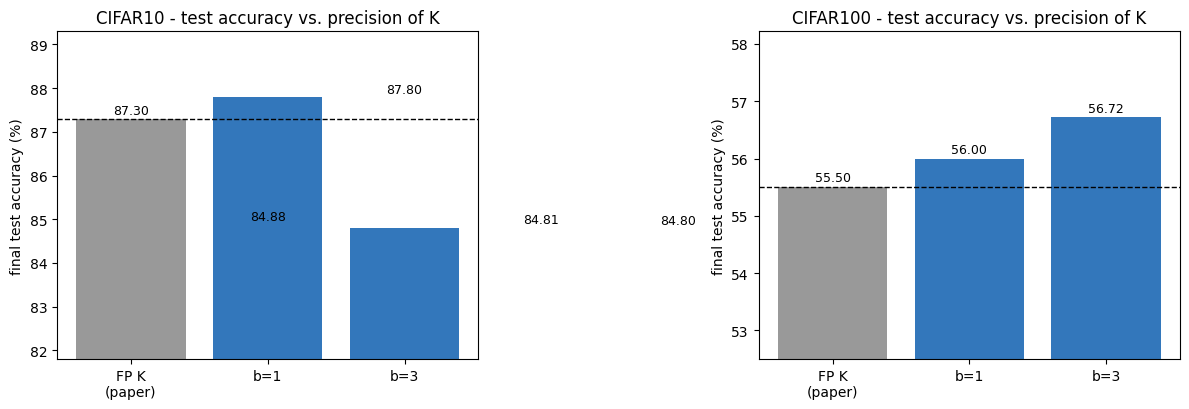

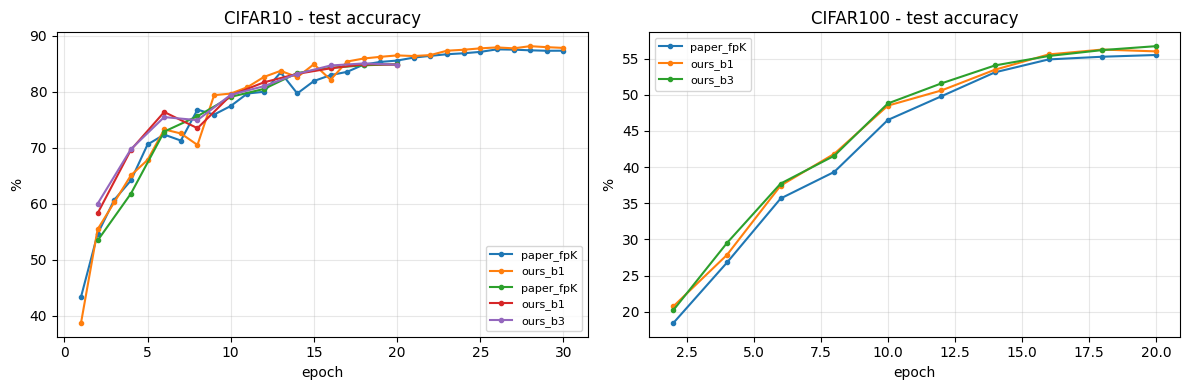

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

rows = []
for rid, r in RESULTS.items():
    if not r.get("done"): continue
    rows.append(dict(Dataset=r["dataset"], Variant=r["variant"], K_bits=r["k_bits"], Final_acc=r["final_acc"], Best_acc=r["best_acc"],
                     Params_M=r["params_m"], T=r["T"], Epochs=r["epochs"], Model=f'{r["depth"]}-{r["embed"]}',
                     Q_rate=r["q_rate"], K_nonzero=r["k_rate"], V_nonzero=r["v_rate"], Attn_ACs_M=r["acs_per_sample"]/1e6,
                     K_mem_KB=r["k_mem_kb_per_sample"], Train_min=r["train_minutes"]))
df = pd.DataFrame(rows)
order = {v["name"]: i for i, v in enumerate(VARIANTS)}
df["_o"] = df["Variant"].map(order).fillna(99)
df = df.sort_values(["Dataset", "_o"]).drop(columns="_o").reset_index(drop=True)
base_acc = df[df.Variant == "paper_fpK"].set_index(["Dataset", "Model", "T", "Epochs"])["Final_acc"]
df["Delta_vs_FP_K"] = [r.Final_acc - base_acc.get((r.Dataset, r.Model, r.T, r.Epochs), np.nan) for r in df.itertuples()]
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(df.round(3)); df.round(4).to_csv(os.path.join(WORK_DIR, "ablation_results.csv"), index=False)

print("\nSmallest bit-width within %.1f points of the paper's full-precision K:" % ACC_TOLERANCE_PP)
for ds in df.Dataset.unique():
    d = df[df.Dataset == ds]; fp = d[d.Variant == "paper_fpK"]; q = d[d.Variant.str.startswith("ours_b")].sort_values("K_bits")
    if fp.empty or q.empty: print(f"  {ds}: need the baseline and at least one quantized run"); continue
    ok = q[q.Delta_vs_FP_K >= -ACC_TOLERANCE_PP]
    if ok.empty: print(f"  {ds}: none within tolerance (best: b={int(q.loc[q.Final_acc.idxmax(),'K_bits'])}, {q.Final_acc.max():.2f}% vs FP {fp.Final_acc.iloc[0]:.2f}%)")
    else:
        r = ok.iloc[0]; print(f"  {ds}: b = {int(r.K_bits)}  ({r.Final_acc:.2f}% vs FP K {fp.Final_acc.iloc[0]:.2f}%, delta {r.Delta_vs_FP_K:+.2f}; K memory {r.K_mem_KB:.0f} KB vs {fp.K_mem_KB.iloc[0]:.0f} KB per sample)")
print("(single seed: differences below ~0.5 points are within run-to-run noise)")

dss = list(df.Dataset.unique())
fig, axes = plt.subplots(1, len(dss), figsize=(6 * len(dss), 4.2), squeeze=False)
for ax, ds in zip(axes[0], dss):
    d = df[df.Dataset == ds]
    labels = ["FP K\n(paper)" if v == "paper_fpK" else f"b={int(b)}" for v, b in zip(d.Variant, d.K_bits)]
    ax.bar(labels, d.Final_acc, color=["#999999" if v == "paper_fpK" else "#3377bb" for v in d.Variant])
    for i, a in enumerate(d.Final_acc): ax.text(i, a + 0.1, f"{a:.2f}", ha="center", fontsize=9)
    fp = d[d.Variant == "paper_fpK"]
    if not fp.empty: ax.axhline(fp.Final_acc.iloc[0], color="k", ls="--", lw=1)
    ax.set_ylim(max(0, d.Final_acc.min() - 3), d.Final_acc.max() + 1.5)
    ax.set_title(f"{ds.upper()} - test accuracy vs. precision of K"); ax.set_ylabel("final test accuracy (%)")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_accuracy_vs_bits.png"), dpi=150); plt.show()

fig, axes = plt.subplots(1, len(dss), figsize=(6 * len(dss), 4), squeeze=False)
for ax, ds in zip(axes[0], dss):
    for rid, r in RESULTS.items():
        if r.get("done") and r["dataset"] == ds:
            h = [x for x in r["hist"] if x["test_acc"] == x["test_acc"]]
            ax.plot([x["epoch"] for x in h], [x["test_acc"] for x in h], marker="o", ms=3, label=r["variant"])
    ax.set_title(f"{ds.upper()} - test accuracy"); ax.set_xlabel("epoch"); ax.set_ylabel("%"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_training_curves.png"), dpi=150); plt.show()

## 8. Efficiency and K analysis (K memory, accumulate ops, firing rates, K levels, learned step sizes)

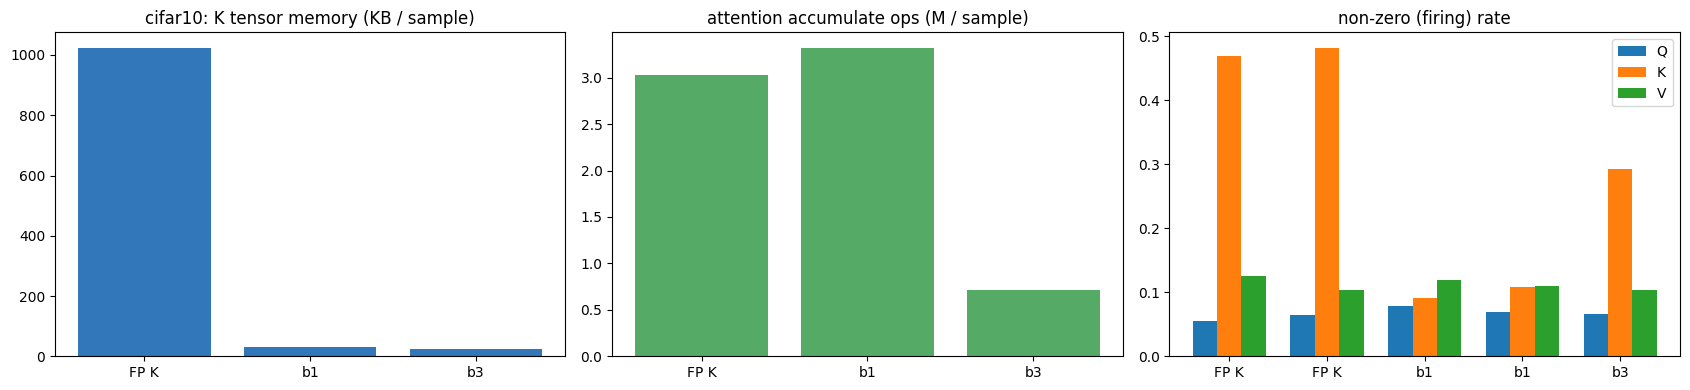

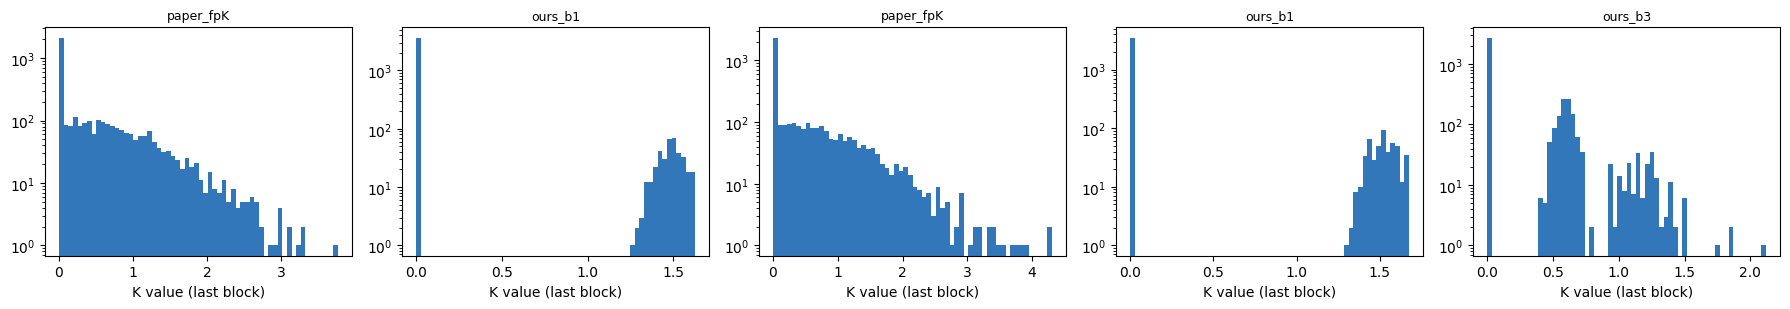

ours_b1: learned step size theta mean 1.382, std 0.148, min 0.915, max 1.732
ours_b1: learned step size theta mean 1.430, std 0.124, min 1.078, max 1.687
ours_b3: learned step size theta mean 0.536, std 0.086, min 0.259, max 0.739


In [18]:
ds0 = df.Dataset.iloc[0]; d0 = df[df.Dataset == ds0].reset_index(drop=True)
names = ["FP K" if v == "paper_fpK" else v.replace("ours_", "") for v in d0.Variant]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(names, d0.K_mem_KB, color="#3377bb"); axes[0].set_title(f"{ds0}: K tensor memory (KB / sample)")
axes[1].bar(names, d0.Attn_ACs_M, color="#55aa66"); axes[1].set_title("attention accumulate ops (M / sample)")
w = 0.25; x = np.arange(len(names))
axes[2].bar(x - w, d0.Q_rate, w, label="Q"); axes[2].bar(x, d0.K_nonzero, w, label="K"); axes[2].bar(x + w, d0.V_nonzero, w, label="V")
axes[2].set_xticks(x); axes[2].set_xticklabels(names); axes[2].legend(); axes[2].set_title("non-zero (firing) rate")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_efficiency.png"), dpi=150); plt.show()

runs = [(rid, r) for rid, r in RESULTS.items() if r.get("done") and r["dataset"] == ds0]
fig, axes = plt.subplots(1, len(runs), figsize=(3.6 * len(runs), 3.2), squeeze=False)
for ax, (rid, r) in zip(axes[0], runs):
    ax.hist(r["k_samples"]["last_block"], bins=60, color="#3377bb"); ax.set_title(r["variant"], fontsize=9)
    ax.set_yscale("log"); ax.set_xlabel("K value (last block)")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_K_distribution.png"), dpi=150); plt.show()

for rid, r in runs:
    if "theta" in r:
        t = np.array(r["theta"]); print(f"{r['variant']}: learned step size theta mean {t.mean():.3f}, std {t.std():.3f}, min {t.min():.3f}, max {t.max():.3f}")

## 9. Notes for the report / viva
* **Why K only?** The paper justifies full-precision K by "more bits = more information capacity", which in the limit removes the point of an SNN, and gives no ablation between binary and full precision. We replace only K by a bounded, 2^b-level spiking neuron (b = 1 and 3 here).
* **Addition-only is preserved:** Q is binary, so Q·Kᵀ only selects and accumulates K entries; V is ternary, so (·)·V only adds or subtracts (verified numerically in section 4).
* **Faster setup vs. the original notebook:** shallower encoder (2 blocks), T = 2, earlier pooling in the patch-splitting module, larger batch, 20 epochs. Absolute accuracies will be somewhat lower than the paper's 4-384 / 100+ epoch setting; the comparison between FP-K and quantized K is still fair because all runs share the same model, seed, schedule and augmentation.
* **Honest limits:** single seed (differences below ~0.5 points are noise); ImageNet-1K is not trained; efficiency numbers are proxies (memory, accumulate counts), not measured energy.